In [9]:
from pathlib import Path
import numpy as np
import torch
from PIL import Image
import json

LOCATION = "montebre"  # cambia con il nome della tua cartella

DATASET_DIR = Path("foto") / LOCATION
OUTPUT_DIR = Path("output") / LOCATION
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if torch.backends.mps.is_available():
    device = "mps"
elif torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"

print(f"Device: {device}")
print(f"Foto in: {DATASET_DIR}")
print(f"Output in: {OUTPUT_DIR}")

Device: mps
Foto in: foto/montebre
Output in: output/montebre


In [10]:
# Trova tutte le immagini .jpg
image_paths = sorted(DATASET_DIR.glob("*.jpg"))

# Aggiungi varianti di estensione (case-insensitive)
image_paths += sorted(DATASET_DIR.glob("*.JPG"))
image_paths += sorted(DATASET_DIR.glob("*.jpeg"))

# Rimuovi duplicati e ordina
image_paths = sorted(set(image_paths))

print(f"Trovate {len(image_paths)} immagini")
print(f"\nPrime 5:")
for p in image_paths[:5]:
    size_kb = p.stat().st_size / 1024
    print(f"  {p.name} ({size_kb:.0f} KB)")

print(f"\nUltime 5:")
for p in image_paths[-5:]:
    size_kb = p.stat().st_size / 1024
    print(f"  {p.name} ({size_kb:.0f} KB)")

Trovate 1780 immagini

Prime 5:
  2726624245427352940_01.jpg (212 KB)
  2726884535804488067_01.jpg (40 KB)
  2727020627170464962_01.jpg (114 KB)
  2727304119917950317_01.jpg (99 KB)
  2728424842913173979_01.jpg (264 KB)

Ultime 5:
  3858410858175271715_01.jpg (558 KB)
  3859387795513449766_01.jpg (392 KB)
  3860036391258589230_01.jpg (314 KB)
  3861194855842369473_01.jpg (892 KB)
  3862297473872398844_01.jpg (322 KB)


In [11]:
from transformers import AutoImageProcessor, AutoModel

model_name = "facebook/dinov2-large"

print(f"Caricamento {model_name}...")
processor = AutoImageProcessor.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name).to(device)
model.eval()

print("Modello DINOv2 ViT-L caricato!")
print(f"Device: {device}")

Caricamento facebook/dinov2-large...


Loading weights:   0%|          | 0/439 [00:00<?, ?it/s]

Modello DINOv2 ViT-L caricato!
Device: mps


In [12]:
from tqdm.notebook import tqdm
from sklearn.preprocessing import normalize

embeddings = []
valid_paths = []
errors = []

with torch.no_grad():
    for path in tqdm(image_paths, desc="Estrazione embedding DINOv2"):
        try:
            image = Image.open(path).convert("RGB")
            inputs = processor(images=image, return_tensors="pt").to(device)
            features = model(**inputs)
            emb = features.pooler_output.cpu().numpy()[0]
            embeddings.append(emb)
            valid_paths.append(path)
        except Exception as e:
            errors.append((path.name, str(e)))

embeddings = np.array(embeddings)
embeddings_normalized = normalize(embeddings)

print(f"\nEmbedding estratti: {embeddings.shape}")
print(f"Errori: {len(errors)}")

np.save(OUTPUT_DIR / "embeddings_dinov2.npy", embeddings_normalized)
paths_str = [str(p) for p in valid_paths]
with open(OUTPUT_DIR / "paths_dinov2.json", "w") as f:
    json.dump(paths_str, f, indent=2)

print(f"Salvati in {OUTPUT_DIR}")

Estrazione embedding DINOv2:   0%|          | 0/1780 [00:00<?, ?it/s]


Embedding estratti: (1780, 1024)
Errori: 0
Salvati in output/montebre


In [13]:
import hdbscan
from collections import Counter

labels = hdbscan.HDBSCAN(
    min_cluster_size=6,
    min_samples=3,
    metric='euclidean',
    cluster_selection_method='eom'
).fit_predict(embeddings_normalized)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print(f"\n=== RISULTATI DINOv2 ===")
print(f"Cluster identificati: {n_clusters}")
print(f"Foto in cluster: {len(labels) - n_noise} ({100*(len(labels) - n_noise)/len(labels):.1f}%)")
print(f"Foto rumore: {n_noise} ({100*n_noise/len(labels):.1f}%)")

print(f"\n=== TUTTI I CLUSTER ===")
counter = Counter(labels)
for cluster_id, count in sorted(counter.items(), key=lambda x: -x[1]):
    if cluster_id == -1:
        continue
    print(f"Cluster {cluster_id:3d}: {count:4d} foto")

cluster_ordinati = [c for c, _ in sorted(counter.items(), key=lambda x: -x[1]) if c != -1]


=== RISULTATI DINOv2 ===
Cluster identificati: 25
Foto in cluster: 785 (44.1%)
Foto rumore: 995 (55.9%)

=== TUTTI I CLUSTER ===
Cluster  23:  290 foto
Cluster  20:  158 foto
Cluster  24:   63 foto
Cluster  15:   34 foto
Cluster   7:   18 foto
Cluster  19:   18 foto
Cluster   3:   17 foto
Cluster   1:   16 foto
Cluster  18:   16 foto
Cluster   4:   16 foto
Cluster   2:   16 foto
Cluster  22:   15 foto
Cluster  12:   13 foto
Cluster  16:   13 foto
Cluster   5:   11 foto
Cluster  11:   10 foto
Cluster  10:    9 foto
Cluster   9:    7 foto
Cluster   0:    7 foto
Cluster  13:    7 foto
Cluster   8:    7 foto
Cluster  21:    6 foto
Cluster  17:    6 foto
Cluster  14:    6 foto
Cluster   6:    6 foto


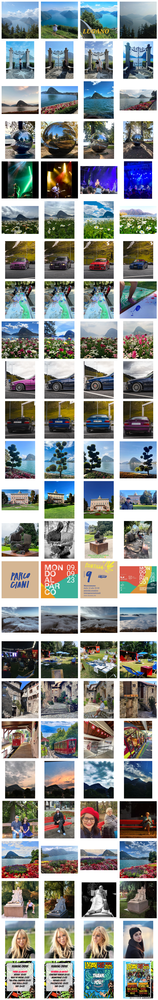

In [14]:
import matplotlib.pyplot as plt

def panoramica_cluster(cluster_ids, n_per_cluster=4):
    n_clusters_show = len(cluster_ids)
    fig, axes = plt.subplots(n_clusters_show, n_per_cluster, 
                              figsize=(n_per_cluster*2.5, n_clusters_show*2.5))
    if n_clusters_show == 1:
        axes = [axes]
    for row, cid in enumerate(cluster_ids):
        indici = np.where(labels == cid)[0]
        cluster_emb = embeddings_normalized[indici]
        centroide = cluster_emb.mean(axis=0)
        centroide = centroide / np.linalg.norm(centroide)
        distanze = np.linalg.norm(cluster_emb - centroide, axis=1)
        indici_ordinati = indici[np.argsort(distanze)][:n_per_cluster]
        for col, idx in enumerate(indici_ordinati):
            img = Image.open(valid_paths[idx])
            axes[row][col].imshow(img)
            axes[row][col].axis('off')
            if col == 0:
                axes[row][col].set_ylabel(f"C{cid}\n({len(indici)})", 
                                            rotation=0, ha='right', va='center', fontsize=10)
    plt.tight_layout()
    plt.show()

panoramica_cluster(cluster_ordinati, n_per_cluster=4)

Cluster validi: [np.int64(23), np.int64(11), np.int64(10), np.int64(9), np.int64(0), np.int64(13)]
Esclusi: [20, 24, 15, 7, 19, 3, 1, 18, 4, 2, 22, 12, 16, 5, 6, 14, 17, 21, 8]

  C23: 290 foto
  C11: 10 foto
  C10: 9 foto
  C9: 7 foto
  C0: 7 foto
  C13: 7 foto


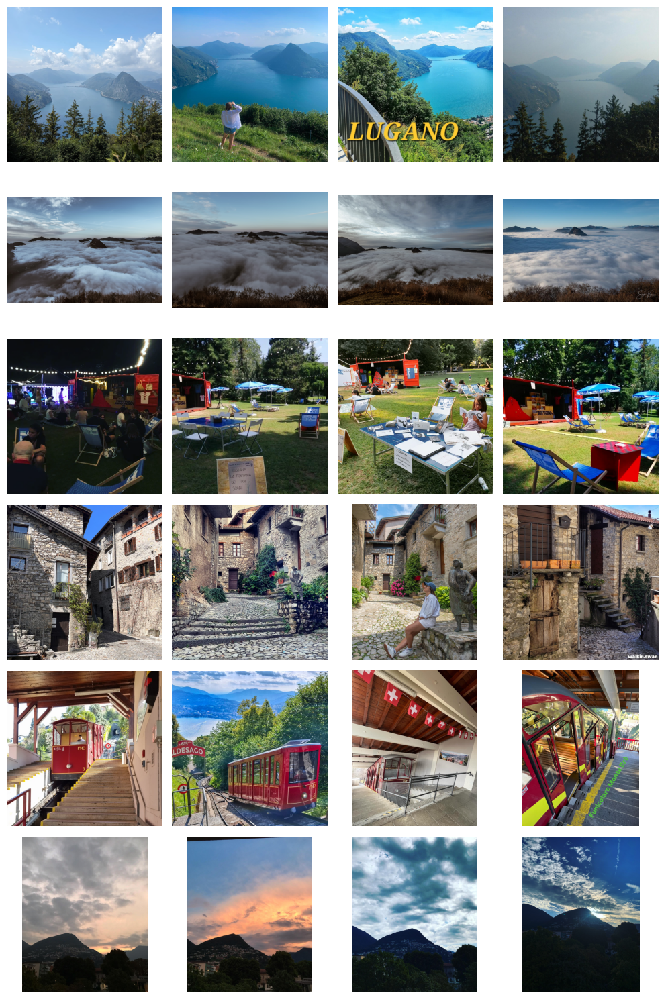

In [15]:
# Escludi cluster spuri
ESCLUSI = [20, 24, 15, 7, 19, 3, 1, 18, 4, 2, 22, 12, 16, 5, 6, 14, 17, 21,8]  # esempio: cluster 3 e 7 non mi interessano
CLUSTER_VALIDI = [c for c in cluster_ordinati if c not in ESCLUSI]

print(f"Cluster validi: {CLUSTER_VALIDI}")
print(f"Esclusi: {ESCLUSI}\n")

for cid in CLUSTER_VALIDI:
    n = list(labels).count(cid)
    print(f"  C{cid}: {n} foto")

# Panoramica visiva dei soli cluster validi
panoramica_cluster(CLUSTER_VALIDI, n_per_cluster=4)

In [16]:
from dotenv import load_dotenv
import os
from google import genai

load_dotenv(override=True)
api_key = os.getenv("GEMINI_API_KEY")

if not api_key:
    print("❌ API key non trovata nel .env")
else:
    print(f"✅ API key caricata ({len(api_key)} caratteri)")
    client = genai.Client(api_key=api_key)
    print("✅ Gemini configurato (nuova libreria)")

✅ API key caricata (39 caratteri)
✅ Gemini configurato (nuova libreria)


In [17]:
import json
import numpy as np
from pathlib import Path

# === COORDINATE PER OGNI LOCATION ===
# Aggiusta cliccando col destro su Google Maps → "Cosa c'è qui?"

LOCATIONS = {
    "parcociani": {
        "hotspot_coords": {
            7: {"lat": 46.00307, "lng": 8.95473, "spread_m": 6},    # Cancello iconico
            8: {"lat": 46.00257, "lng": 8.95458, "spread_m": 50},   # Monte San Salvatore vista
            3: {"lat": 46.00342, "lng": 8.95379, "spread_m": 4},    # Sfera riflettente
            5: {"lat": 46.00362, "lng": 8.95425, "spread_m": 25},   # Tulipani
            2: {"lat": 46.00388, "lng": 8.95501, "spread_m": 12},   # Villa Ciani
            9: {"lat": 46.00295, "lng": 8.95398, "spread_m": 6},    # Topiaria
            0: {"lat": 46.00408, "lng": 8.95460, "spread_m": 30},   # LongLake Festival
            4: {"lat": 46.00378, "lng": 8.95402, "spread_m": 20},   # Azalee
            1: {"lat": 46.00335, "lng": 8.95445, "spread_m": 15},   # Cervi luminosi
            6: {"lat": 46.00365, "lng": 8.95436, "spread_m": 25},   # Papaveri
        }
    },
    "montebre": {
        "hotspot_coords": {
            # IMPORTANTE: questi cluster_id devono corrispondere a quelli nel tuo hotspots.json di montebre
            # Le coordinate sotto sono stimate — aggiustale dopo
            # Se non conosci gli ID, esegui prima la cella e vedi l'errore, poi aggiusta
        }
    }
}

# === PRIMA: scopriamo quali cluster ha Monte Brè ===
montebre_hotspots_path = Path("output/montebre/hotspots.json")
if montebre_hotspots_path.exists():
    with open(montebre_hotspots_path) as f:
        mb_hotspots = json.load(f)
    print("=== CLUSTER MONTE BRÈ ===")
    for h in mb_hotspots:
        print(f"  C{h['cluster_id']} ({h['size']} foto): {h['label']}")
    print("\nCopia gli ID sopra e assegna coordinate nel dizionario LOCATIONS['montebre']")
    print("Per ora genero con coordinate stimate attorno alla vetta.\n")
    
    # Coordinate stimate attorno a Monte Brè
    # Vetta: 46.0073, 8.9873
    # Panoramica sud (verso lago): 46.0065, 8.9870
    # Funicolare arrivo: 46.0070, 8.9865
    base_lat = 46.0070
    base_lng = 8.9870
    
    for i, h in enumerate(mb_hotspots):
        cid = h["cluster_id"]
        # Distribuisci i cluster in un arco attorno alla vetta
        angle = (i / len(mb_hotspots)) * 2 * np.pi
        offset = 0.0003  # ~30m
        LOCATIONS["montebre"]["hotspot_coords"][cid] = {
            "lat": base_lat + np.sin(angle) * offset,
            "lng": base_lng + np.cos(angle) * offset,
            "spread_m": 20
        }

# === GENERA GEOJSON COMBINATO ===
M_TO_DEG_LAT = 1 / 111000
M_TO_DEG_LNG = 1 / (111000 * np.cos(np.radians(46.0)))

features = []
np.random.seed(42)

for location_name, location_data in LOCATIONS.items():
    hotspots_path = Path("output") / location_name / "hotspots.json"
    if not hotspots_path.exists():
        print(f"⚠️ {hotspots_path} non trovato, salto")
        continue
    
    with open(hotspots_path) as f:
        hotspots = json.load(f)
    
    coords_map = location_data["hotspot_coords"]
    
    for h in hotspots:
        cid = h["cluster_id"]
        if cid not in coords_map:
            print(f"  ⚠️ {location_name} C{cid} ({h['label']}): coordinate mancanti, salto")
            continue
        
        coords = coords_map[cid]
        n_photos = h["size"]
        spread = coords["spread_m"]
        
        for i in range(n_photos):
            offset_lat = np.random.normal(0, spread / 2) * M_TO_DEG_LAT
            offset_lng = np.random.normal(0, spread / 2) * M_TO_DEG_LNG
            
            photo = h["representative_photos"][i % len(h["representative_photos"])]
            
            feature = {
                "type": "Feature",
                "geometry": {
                    "type": "Point",
                    "coordinates": [
                        coords["lng"] + offset_lng,
                        coords["lat"] + offset_lat
                    ]
                },
                "properties": {
                    "cluster_id": cid,
                    "location": location_name,
                    "label": h["label"],
                    "description": h["description"],
                    "photo_path": photo,
                    "cluster_size": n_photos
                }
            }
            features.append(feature)
    
    print(f"✅ {location_name}: {sum(h['size'] for h in hotspots if h['cluster_id'] in coords_map)} punti generati")

geojson = {
    "type": "FeatureCollection",
    "features": features
}

# Salva nella cartella output principale
output_path = Path("output/geo_data_all.geojson")
with open(output_path, "w") as f:
    json.dump(geojson, f, indent=2)

print(f"\n=== TOTALE: {len(features)} punti salvati in {output_path} ===")

✅ parcociani: 176 punti generati
⚠️ output/montebre/hotspots.json non trovato, salto

=== TOTALE: 176 punti salvati in output/geo_data_all.geojson ===


In [19]:
def descrivi_cluster_gemini(cluster_id, n_foto=4):
    indici = np.where(labels == cluster_id)[0]
    cluster_emb = embeddings_normalized[indici]
    centroide = cluster_emb.mean(axis=0)
    centroide = centroide / np.linalg.norm(centroide)
    distanze = np.linalg.norm(cluster_emb - centroide, axis=1)
    indici_ordinati = indici[np.argsort(distanze)][:n_foto]
    
    images = [Image.open(valid_paths[idx]) for idx in indici_ordinati]
    
    prompt = """These photos were clustered together by an AI as visually similar tourist photos from Parco Ciani, a public park in Lugano, Switzerland.

Analyze them and identify the common subject — likely an iconic landmark or recurring view.

Respond with ONLY a valid JSON object (no markdown fences, no extra text):
{
  "label": "short label of 3-5 words in English",
  "description": "1-2 sentences describing what is depicted",
  "search_prompt": "a concise visual description suitable for an object detection model",
  "confidence": 0.0
}

confidence is a float 0-1 indicating how coherent the cluster is."""
    
    response = client.models.generate_content(
        model='gemini-3-flash-preview',
        contents=[prompt] + images
    )
    return response.text

# Test
cid_test = cluster_ordinati[0]
print(f"Test su Cluster {cid_test}...\n")
result = descrivi_cluster_gemini(cid_test, n_foto=4)
print(result)

Test su Cluster 23...

{
  "label": "Panorama of Lake Lugano",
  "description": "Panoramic scenic views of Lake Lugano taken from an elevated viewpoint, prominently featuring the Melide causeway and the peak of Monte San Salvatore. The images capture the vastness of the lake and the surrounding Swiss mountains.",
  "search_prompt": "high-angle panoramic view of Lake Lugano with Melide causeway and mountain peaks",
  "confidence": 1.0
}


In [20]:
CLUSTER_VALIDI = list(cluster_ordinati)
print(f"Cluster da processare: {CLUSTER_VALIDI}")

Cluster da processare: [np.int64(23), np.int64(20), np.int64(24), np.int64(15), np.int64(7), np.int64(19), np.int64(3), np.int64(1), np.int64(18), np.int64(4), np.int64(2), np.int64(22), np.int64(12), np.int64(16), np.int64(5), np.int64(11), np.int64(10), np.int64(9), np.int64(0), np.int64(13), np.int64(8), np.int64(21), np.int64(17), np.int64(14), np.int64(6)]


In [21]:
import re
import time

hotspots = []

for cid in CLUSTER_VALIDI:
    print(f"Processo Cluster {cid}...")
    try:
        raw_response = descrivi_cluster_gemini(cid, n_foto=4)
        cleaned = re.sub(r'```json\s*|\s*```', '', raw_response).strip()
        data = json.loads(cleaned)
        
        indici = np.where(labels == cid)[0]
        cluster_emb = embeddings_normalized[indici]
        centroide = cluster_emb.mean(axis=0)
        centroide = centroide / np.linalg.norm(centroide)
        distanze = np.linalg.norm(cluster_emb - centroide, axis=1)
        indici_ordinati = indici[np.argsort(distanze)]
        rappresentative = [str(valid_paths[idx]) for idx in indici_ordinati[:8]]
        
        hotspot = {
            "cluster_id": int(cid),
            "size": int(len(indici)),
            "label": data.get("label", ""),
            "description": data.get("description", ""),
            "search_prompt": data.get("search_prompt", ""),
            "confidence": float(data.get("confidence", 0)),
            "representative_photos": rappresentative
        }
        hotspots.append(hotspot)
        print(f"  ✓ {hotspot['label']} (conf: {hotspot['confidence']})")
        
        time.sleep(2)  # rate limit Gemini gratuito
        
    except json.JSONDecodeError as e:
        print(f"  ✗ Errore parsing JSON: {e}")
        print(f"  Raw: {raw_response[:300]}")
    except Exception as e:
        print(f"  ✗ Errore: {e}")

# Ordina per dimensione
hotspots.sort(key=lambda h: -h["size"])

# Salva il file finale
hotspots_path = OUTPUT_DIR / "hotspots.json"
with open(hotspots_path, "w") as f:
    json.dump(hotspots, f, indent=2, ensure_ascii=False)

print(f"\n=== HOTSPOT SALVATI in {hotspots_path} ===\n")
for h in hotspots:
    print(f"  C{h['cluster_id']:2d} ({h['size']:3d} foto): {h['label']:40s} [conf: {h['confidence']:.2f}]")

Processo Cluster 23...
  ✓ View of Monte San Salvatore (conf: 1.0)
Processo Cluster 20...
  ✓ Wrought-iron gate in Parco Ciani (conf: 1.0)
Processo Cluster 24...
  ✓ Monte San Salvatore from Parco Ciani (conf: 1.0)
Processo Cluster 15...
  ✓ Sfera sculpture by Helidon Xhixha (conf: 1.0)
Processo Cluster 7...
  ✓ Live music performance (conf: 1.0)
Processo Cluster 19...
  ✓ Poppies at Parco Ciani (conf: 1.0)
Processo Cluster 3...
  ✓ Modified BMW E36 cars (conf: 1.0)
Processo Cluster 1...
  ✓ Outdoor community painting workshop (conf: 0.95)
Processo Cluster 18...
  ✓ Monte San Salvatore mountain view (conf: 1.0)
Processo Cluster 4...
  ✓ BMW E36 front wheel profile (conf: 1.0)
Processo Cluster 2...
  ✓ BMW E36 rear view (conf: 1.0)
Processo Cluster 22...
  ✓ Cloud-pruned tree overlooking Lake Lugano (conf: 1.0)
Processo Cluster 12...
  ✓ Villa Ciani in Lugano (conf: 1.0)
Processo Cluster 16...
  ✓ Digital Nomad metal sculpture (conf: 1.0)
Processo Cluster 5...
  ✓ Event posters for Parc

In [2]:
# === Salva mapping completo cluster → foto ===
import json

# Usa solo i 3 cluster che ci servono
CLUSTER_EXPORT = [23, 11, 10, 9, 0, 13]

cluster_photos = {}
for cid in CLUSTER_EXPORT:
    indici = np.where(labels == cid)[0]
    cluster_photos[str(cid)] = [str(valid_paths[i]) for i in indici]

# Salva
with open(OUTPUT_DIR / "cluster_photos.json", "w") as f:
    json.dump(cluster_photos, f, indent=2)

# Verifica
for cid, photos in cluster_photos.items():
    print(f"Cluster {cid}: {len(photos)} foto")
print(f"\nSalvato in {OUTPUT_DIR / 'cluster_photos.json'}")

NameError: name 'np' is not defined